In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# Project paths
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "processed"

# Load NAV and benchmark data
nav_df = pd.read_csv(DATA_DIR / "cleaned_nav_history.csv")
benchmark_df = pd.read_csv(DATA_DIR / "cleaned_benchmark_indices.csv")

# Convert dates and ensure numeric values
nav_df["date"] = pd.to_datetime(nav_df["date"], errors="coerce")
nav_df["nav"] = pd.to_numeric(nav_df["nav"], errors="coerce")

benchmark_df["date"] = pd.to_datetime(
    benchmark_df["date"], errors="coerce"
)
benchmark_df["close_value"] = pd.to_numeric(
    benchmark_df["close_value"], errors="coerce"
)

print("NAV dataset shape:", nav_df.shape)
print("Unique schemes:", nav_df["amfi_code"].nunique())
print("Benchmark dataset shape:", benchmark_df.shape)
print("Available indices:", sorted(benchmark_df["index_name"].unique()))

NAV dataset shape: (46000, 3)
Unique schemes: 40
Benchmark dataset shape: (8050, 3)
Available indices: ['BSE_SMALLCAP', 'CRISIL_GILT', 'CRISIL_LIQUID', 'NIFTY100', 'NIFTY50', 'NIFTY500', 'NIFTY_MIDCAP150']


Duplicate scheme-date records: 0

Daily Return Summary
count    45960.000000
mean         0.000631
std          0.010290
min         -0.058102
25%         -0.005042
50%          0.000340
75%          0.006324
max          0.064713
Name: daily_return, dtype: float64

Missing daily returns: 40
Infinite returns: 0
Negative NAV values: 0
Zero NAV values: 0
Absolute daily returns above 5%: 9


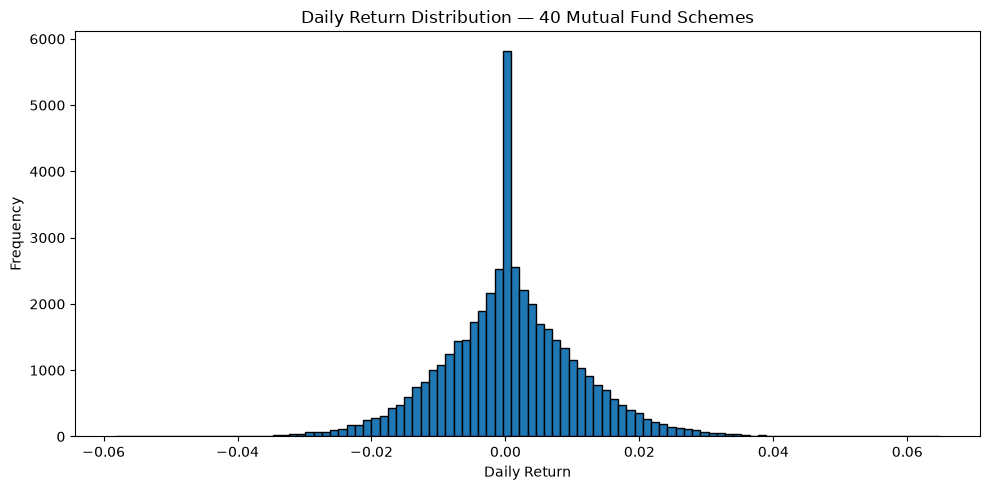

In [2]:
# Sort NAV observations by scheme and date
nav_df = nav_df.sort_values(
    ["amfi_code", "date"]
).copy()

# Check for duplicate scheme-date combinations
duplicates = nav_df.duplicated(
    subset=["amfi_code", "date"]
).sum()

print("Duplicate scheme-date records:", duplicates)

# Calculate daily returns separately for each scheme
nav_df["daily_return"] = (
    nav_df.groupby("amfi_code")["nav"]
    .pct_change(fill_method=None)
)

# Validate the results
returns = nav_df["daily_return"].dropna()

print("\nDaily Return Summary")
print(returns.describe())

print("\nMissing daily returns:", nav_df["daily_return"].isna().sum())
print("Infinite returns:", np.isinf(returns).sum())
print("Negative NAV values:", (nav_df["nav"] < 0).sum())
print("Zero NAV values:", (nav_df["nav"] == 0).sum())

# Count returns outside a broad 5% daily-move threshold
large_moves = (returns.abs() > 0.05).sum()
print("Absolute daily returns above 5%:", large_moves)

# Plot the return distribution
plt.figure(figsize=(10, 5))
plt.hist(returns, bins=100, edgecolor="black")
plt.title("Daily Return Distribution — 40 Mutual Fund Schemes")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [3]:
# STEP 5: Calculate CAGR for all available fund periods

# Ensure NAV data is sorted
nav_sorted = nav_df.sort_values(
    ["amfi_code", "date"]
).copy()

# Latest date available in the dataset
analysis_end_date = nav_sorted["date"].max()

print("Analysis end date:", analysis_end_date.date())

cagr_results = []

for scheme, group in nav_sorted.groupby("amfi_code"):
    group = group.dropna(subset=["date", "nav"]).sort_values("date")

    # Latest available NAV for this scheme
    end_row = group.iloc[-1]
    end_date = end_row["date"]
    end_nav = end_row["nav"]

    result = {
        "amfi_code": scheme,
        "end_date": end_date,
        "end_nav": end_nav
    }

    for years in [1, 3, 5]:
        target_date = end_date - pd.DateOffset(years=years)

        # Use the latest NAV on or before the target date
        eligible = group[group["date"] <= target_date]

        if eligible.empty:
            result[f"CAGR_{years}Y"] = np.nan
            continue

        start_row = eligible.iloc[-1]
        start_date = start_row["date"]
        start_nav = start_row["nav"]

        actual_years = (end_date - start_date).days / 365.25

        if start_nav <= 0 or actual_years <= 0:
            result[f"CAGR_{years}Y"] = np.nan
        else:
            result[f"CAGR_{years}Y"] = (
                (end_nav / start_nav) ** (1 / actual_years) - 1
            )

    cagr_results.append(result)

cagr_df = pd.DataFrame(cagr_results)

# Display percentage values for readability
cagr_display = cagr_df.copy()

for col in ["CAGR_1Y", "CAGR_3Y", "CAGR_5Y"]:
    cagr_display[col] = cagr_display[col] * 100

print("\nCAGR comparison across all schemes (%)")
display(
    cagr_display[
        ["amfi_code", "CAGR_1Y", "CAGR_3Y", "CAGR_5Y"]
    ].round(2)
)

print("\nAvailable CAGR values:")
print(cagr_df[["CAGR_1Y", "CAGR_3Y", "CAGR_5Y"]].notna().sum())

print("\nSchemes analysed:", cagr_df["amfi_code"].nunique())

Analysis end date: 2026-05-29

CAGR comparison across all schemes (%)


,amfi_code,CAGR_1Y,CAGR_3Y,CAGR_5Y
0,100016,-2.23,1.29,NaN
1,100025,3.71,3.92,NaN
2,100033,53.28,32.43,NaN
3,101206,47.96,28.96,NaN
4,101207,-24.00,-4.15,NaN
5,101208,7.24,6.31,NaN
6,102885,20.22,19.66,NaN
7,102886,-16.81,-0.77,NaN
8,102887,13.59,25.55,NaN
9,118632,34.01,22.65,NaN



Available CAGR values:
CAGR_1Y    40
CAGR_3Y    40
CAGR_5Y     0
dtype: int64

Schemes analysed: 40


In [4]:
# STEP 6: Calculate Sharpe and Sortino Ratios

TRADING_DAYS = 252
RISK_FREE_ANNUAL = 0.065

# Convert annual risk-free rate to an equivalent daily rate
risk_free_daily = (1 + RISK_FREE_ANNUAL) ** (1 / TRADING_DAYS) - 1

risk_results = []

for scheme, group in nav_df.groupby("amfi_code"):
    daily_returns = (
        group.sort_values("date")["daily_return"]
        .dropna()
    )

    if len(daily_returns) < 2:
        risk_results.append({
            "amfi_code": scheme,
            "Sharpe_Ratio": np.nan,
            "Sortino_Ratio": np.nan
        })
        continue

    # Daily excess returns
    excess_returns = daily_returns - risk_free_daily

    # Sharpe Ratio
    daily_std = daily_returns.std(ddof=1)

    sharpe = (
        excess_returns.mean() / daily_std * np.sqrt(TRADING_DAYS)
        if daily_std > 0 else np.nan
    )

    # Sortino Ratio: downside deviation relative to daily risk-free rate
    downside_excess = excess_returns[excess_returns < 0]

    downside_deviation = (
        np.sqrt(np.mean(downside_excess ** 2))
        if len(downside_excess) > 0 else np.nan
    )

    sortino = (
        excess_returns.mean() / downside_deviation * np.sqrt(TRADING_DAYS)
        if pd.notna(downside_deviation) and downside_deviation > 0
        else np.nan
    )

    risk_results.append({
        "amfi_code": scheme,
        "Sharpe_Ratio": sharpe,
        "Sortino_Ratio": sortino
    })

risk_df = pd.DataFrame(risk_results)

print("Schemes analysed:", risk_df["amfi_code"].nunique())
print("\nMissing ratios:")
print(risk_df[["Sharpe_Ratio", "Sortino_Ratio"]].isna().sum())

print("\nTop 10 funds by Sharpe Ratio:")
display(
    risk_df.sort_values("Sharpe_Ratio", ascending=False)
    .head(10)
    .round(3)
)

print("\nTop 10 funds by Sortino Ratio:")
display(
    risk_df.sort_values("Sortino_Ratio", ascending=False)
    .head(10)
    .round(3)
)

Schemes analysed: 40

Missing ratios:
Sharpe_Ratio     0
Sortino_Ratio    0
dtype: int64

Top 10 funds by Sharpe Ratio:


,amfi_code,Sharpe_Ratio,Sortino_Ratio
34,148567,1.463,1.478
30,120843,1.319,1.396
36,148569,1.246,1.315
19,119551,1.223,1.278
25,120505,1.191,1.250
38,149323,1.143,1.147
2,100033,1.104,1.134
9,118632,1.096,1.121
3,101206,1.041,1.085
24,120504,1.041,1.060



Top 10 funds by Sortino Ratio:


,amfi_code,Sharpe_Ratio,Sortino_Ratio
34,148567,1.463,1.478
30,120843,1.319,1.396
36,148569,1.246,1.315
19,119551,1.223,1.278
25,120505,1.191,1.250
38,149323,1.143,1.147
2,100033,1.104,1.134
9,118632,1.096,1.121
3,101206,1.041,1.085
16,119094,1.009,1.061


In [5]:
# STEP 7: Calculate Alpha and Beta against Nifty 100

benchmark_name = "NIFTY100"

# Prepare Nifty 100 daily returns
benchmark_returns = (
    benchmark_df.loc[
        benchmark_df["index_name"] == benchmark_name,
        ["date", "close_value"]
    ]
    .sort_values("date")
    .drop_duplicates(subset=["date"])
    .copy()
)

benchmark_returns["benchmark_return"] = (
    benchmark_returns["close_value"].pct_change(fill_method=None)
)

benchmark_returns = benchmark_returns[
    ["date", "benchmark_return"]
].dropna()

alpha_beta_results = []

for scheme, group in nav_df.groupby("amfi_code"):
    fund_returns = group[["date", "daily_return"]].copy()

    # Align fund and benchmark returns by date
    aligned = fund_returns.merge(
        benchmark_returns,
        on="date",
        how="inner"
    ).dropna()

    # Require enough observations for a meaningful regression
    if len(aligned) < 30:
        alpha_beta_results.append({
            "amfi_code": scheme,
            "Alpha_Annualized": np.nan,
            "Beta": np.nan,
            "Observations": len(aligned)
        })
        continue

    regression = stats.linregress(
        aligned["benchmark_return"],
        aligned["daily_return"]
    )

    alpha_beta_results.append({
        "amfi_code": scheme,
        "Alpha_Annualized": regression.intercept * 252,
        "Beta": regression.slope,
        "Observations": len(aligned)
    })

alpha_beta_df = pd.DataFrame(alpha_beta_results)

print("Schemes analysed:", alpha_beta_df["amfi_code"].nunique())
print("\nMissing values:")
print(alpha_beta_df[["Alpha_Annualized", "Beta"]].isna().sum())

print("\nTop 10 funds by annualized Alpha:")
display(
    alpha_beta_df.sort_values(
        "Alpha_Annualized", ascending=False
    ).head(10).round(4)
)

print("\nBeta summary:")
display(alpha_beta_df["Beta"].describe().round(4))

Schemes analysed: 40

Missing values:
Alpha_Annualized    0
Beta                0
dtype: int64

Top 10 funds by annualized Alpha:


,amfi_code,Alpha_Annualized,Beta,Observations
21,119598,0.3034,-0.0232,1149
39,149324,0.3006,0.0115,1149
25,120505,0.2926,0.0005,1149
36,148569,0.2827,0.0181,1149
30,120843,0.2733,-0.0228,1149
2,100033,0.2720,0.0051,1149
34,148567,0.2698,0.0237,1149
38,149323,0.2660,-0.0025,1149
16,119094,0.2608,-0.0663,1149
19,119551,0.2320,-0.0318,1149



Beta summary:


count    40.0000
mean     -0.0020
std       0.0352
min      -0.0670
25%      -0.0239
50%      -0.0001
75%       0.0170
max       0.1035
Name: Beta, dtype: float64

In [6]:
# STEP 8: Maximum Drawdown and Worst Drawdown Period

drawdown_results = []

for scheme, group in nav_df.groupby("amfi_code"):
    group = group.sort_values("date").reset_index(drop=True).copy()

    # Calculate the running peak NAV
    group["running_peak"] = group["nav"].cummax()

    # Calculate drawdown relative to the running peak
    group["drawdown"] = (
        group["nav"] / group["running_peak"]
    ) - 1

    # Find the date of the maximum drawdown
    trough_position = group["drawdown"].idxmin()
    max_drawdown = group.loc[trough_position, "drawdown"]
    trough_date = group.loc[trough_position, "date"]

    # Find the previous peak corresponding to this trough
    peak_nav = group.loc[trough_position, "running_peak"]

    peak_candidates = group.loc[
        :trough_position
    ].loc[
        group.loc[:trough_position, "nav"] == peak_nav
    ]

    peak_date = peak_candidates.iloc[-1]["date"]

    drawdown_results.append({
        "amfi_code": scheme,
        "Max_Drawdown": max_drawdown,
        "Peak_Date": peak_date,
        "Trough_Date": trough_date,
        "Drawdown_Days": (trough_date - peak_date).days
    })

drawdown_df = pd.DataFrame(drawdown_results)

print("Schemes analysed:", drawdown_df["amfi_code"].nunique())

print("\nTop 10 funds with the smallest drawdowns:")
display(
    drawdown_df.sort_values(
        "Max_Drawdown", ascending=False
    ).head(10).round(4)
)

print("\nTop 10 funds with the largest drawdowns:")
display(
    drawdown_df.sort_values(
        "Max_Drawdown", ascending=True
    ).head(10).round(4)
)

print("\nMissing values:")
print(drawdown_df.isna().sum())

Schemes analysed: 40

Top 10 funds with the smallest drawdowns:


C:\Users\HP\AppData\Local\Temp\ipykernel_26708\3291092835.py:48: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(10).round(4)


,amfi_code,Max_Drawdown,Peak_Date,Trough_Date,Drawdown_Days
27,120507,-0.0010,2025-10-16,2025-10-20,4
31,120844,-0.0012,2024-04-12,2024-04-30,18
5,101208,-0.0016,2023-09-05,2023-09-12,7
1,100025,-0.0431,2023-05-23,2023-07-28,66
18,119120,-0.0433,2024-09-16,2025-04-01,197
13,118636,-0.0832,2023-02-09,2024-02-09,365
6,102885,-0.1086,2022-02-03,2022-03-29,54
34,148567,-0.1127,2023-07-11,2023-10-20,101
3,101206,-0.1129,2023-04-24,2023-07-05,72
12,118635,-0.1165,2022-01-03,2022-06-09,157



Top 10 funds with the largest drawdowns:


C:\Users\HP\AppData\Local\Temp\ipykernel_26708\3291092835.py:55: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).head(10).round(4)


,amfi_code,Max_Drawdown,Peak_Date,Trough_Date,Drawdown_Days
22,119599,-0.5257,2023-01-17,2025-10-28,1015
17,119095,-0.5168,2025-05-22,2026-05-11,354
4,101207,-0.3545,2024-11-21,2026-05-11,536
39,149324,-0.3117,2024-05-03,2025-01-03,245
21,119598,-0.2871,2024-08-28,2025-05-14,259
7,102886,-0.2800,2025-01-07,2026-04-27,475
0,100016,-0.2473,2022-03-30,2022-09-15,169
29,120842,-0.2400,2023-11-09,2024-10-17,343
11,118634,-0.2334,2025-04-09,2026-02-20,317
15,119093,-0.2175,2022-02-24,2023-05-22,452



Missing values:
amfi_code        0
Max_Drawdown     0
Peak_Date        0
Trough_Date      0
Drawdown_Days    0
dtype: int64


In [7]:
# STEP 9: Inspect Fund Master Dataset

fund_master_path = DATA_DIR / "cleaned_fund_master.csv"

fund_master_df = pd.read_csv(fund_master_path)

print("Dataset shape:", fund_master_df.shape)
print("\nAvailable columns:")
print(fund_master_df.columns.tolist())

print("\nFirst 5 rows:")
display(fund_master_df.head())

Dataset shape: (40, 15)

Available columns:
['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']

First 5 rows:


,amfi_code,fund_house,scheme_name,category,sub_category,plan,launch_date,benchmark,expense_ratio_pct,exit_load_pct,min_sip_amount,min_lumpsum_amount,fund_manager,risk_category,sebi_category_code
0,100016,HDFC Mutual Fund,HDFC Top 100 Fund - Regular Plan - Growth,Equity,Large Cap,Regular,1996-09-11,NIFTY 100 TRI,1.55,1.0,500,1000,Rahul Baijal,Moderate,EC01
1,100025,HDFC Mutual Fund,HDFC Short Term Debt Fund - Regular - Growth,Debt,Short Duration,Regular,2002-06-25,CRISIL Short Term Bond Index,0.56,0.5,500,1000,Anil Bamboli,Low,DC02
2,100033,HDFC Mutual Fund,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,Mid Cap,Regular,2007-06-25,NIFTY Midcap 150 TRI,1.38,1.0,500,1000,Chirag Setalvad,High,EC02
3,101206,Aditya Birla Sun Life MF,ABSL Frontline Equity Fund - Regular - Growth,Equity,Large Cap,Regular,2002-08-30,NIFTY 100 TRI,1.60,1.0,500,1000,Mahesh Patil,Moderate,EC01
4,101207,Aditya Birla Sun Life MF,ABSL Small Cap Fund - Regular - Growth,Equity,Small Cap,Regular,2007-05-31,BSE 250 SmallCap TRI,1.53,1.0,500,1000,Mircea Ciobanu,Very High,EC03


In [8]:

# STEP 10: Validate Fund Master Data

print("Column data types:")
display(fund_master_df.dtypes)

print("\nCheck important fields for missing values:")
display(
    fund_master_df[
        [
            "amfi_code",
            "scheme_name",
            "category",
            "plan",
            "expense_ratio_pct",
            "benchmark"
        ]
    ].isna().sum()
)

print("\nCheck expense ratio values:")
print(
    fund_master_df["expense_ratio_pct"]
    .describe()
    .round(3)
)

print("\nInspect the rows that looked misaligned:")
display(
    fund_master_df.loc[
        fund_master_df["amfi_code"].isin([101206, 101207]),
        [
            "amfi_code",
            "scheme_name",
            "category",
            "sub_category",
            "plan",
            "launch_date",
            "benchmark",
            "expense_ratio_pct"
        ]
    ].to_string(index=False)
)



Column data types:


amfi_code               int64
fund_house                str
scheme_name               str
category                  str
sub_category              str
plan                      str
launch_date               str
benchmark                 str
expense_ratio_pct     float64
exit_load_pct         float64
min_sip_amount          int64
min_lumpsum_amount      int64
fund_manager              str
risk_category             str
sebi_category_code        str
dtype: object


Check important fields for missing values:


amfi_code            0
scheme_name          0
category             0
plan                 0
expense_ratio_pct    0
benchmark            0
dtype: int64


Check expense ratio values:
count    40.000
mean      1.237
std       0.387
min       0.550
25%       0.788
50%       1.425
75%       1.540
max       1.640
Name: expense_ratio_pct, dtype: float64

Inspect the rows that looked misaligned:


' amfi_code                                   scheme_name category sub_category    plan launch_date            benchmark  expense_ratio_pct\n    101206 ABSL Frontline Equity Fund - Regular - Growth   Equity    Large Cap Regular  2002-08-30        NIFTY 100 TRI               1.60\n    101207        ABSL Small Cap Fund - Regular - Growth   Equity    Small Cap Regular  2007-05-31 BSE 250 SmallCap TRI               1.53'

In [10]:

# STEP 11: Identify Existing Performance DataFrames

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataFrame: {name}")
        print(f"Shape: {obj.shape}")
        print(f"Columns: {obj.columns.tolist()}")




DataFrame: nav_df
Shape: (46000, 4)
Columns: ['amfi_code', 'date', 'nav', 'daily_return']

DataFrame: benchmark_df
Shape: (8050, 3)
Columns: ['date', 'index_name', 'close_value']

DataFrame: nav_sorted
Shape: (46000, 4)
Columns: ['amfi_code', 'date', 'nav', 'daily_return']

DataFrame: group
Shape: (1150, 6)
Columns: ['amfi_code', 'date', 'nav', 'daily_return', 'running_peak', 'drawdown']

DataFrame: eligible
Shape: (0, 4)
Columns: ['amfi_code', 'date', 'nav', 'daily_return']

DataFrame: cagr_df
Shape: (40, 6)
Columns: ['amfi_code', 'end_date', 'end_nav', 'CAGR_1Y', 'CAGR_3Y', 'CAGR_5Y']

DataFrame: cagr_display
Shape: (40, 6)
Columns: ['amfi_code', 'end_date', 'end_nav', 'CAGR_1Y', 'CAGR_3Y', 'CAGR_5Y']

DataFrame: risk_df
Shape: (40, 3)
Columns: ['amfi_code', 'Sharpe_Ratio', 'Sortino_Ratio']

DataFrame: benchmark_returns
Shape: (1149, 2)
Columns: ['date', 'benchmark_return']

DataFrame: fund_returns
Shape: (1150, 2)
Columns: ['date', 'daily_return']

DataFrame: aligned
Shape: (1149, 

In [11]:

# STEP 12: Check DataFrames Required for the Fund Scorecard

required_names = [
    "cagr_df",
    "fund_master_df",
    "alpha_beta_df",
    "drawdown_df"
]

for name in required_names:
    if name in globals():
        df = globals()[name]
        print(f"\n{name}: {df.shape}")
        print("Columns:", df.columns.tolist())
    else:
        print(f"\n{name}: NOT FOUND")




cagr_df: (40, 6)
Columns: ['amfi_code', 'end_date', 'end_nav', 'CAGR_1Y', 'CAGR_3Y', 'CAGR_5Y']

fund_master_df: (40, 15)
Columns: ['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']

alpha_beta_df: (40, 4)
Columns: ['amfi_code', 'Alpha_Annualized', 'Beta', 'Observations']

drawdown_df: (40, 5)
Columns: ['amfi_code', 'Max_Drawdown', 'Peak_Date', 'Trough_Date', 'Drawdown_Days']


In [14]:
# Find DataFrames containing Sharpe or Sortino results

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if any(
            "sharpe" in col.lower() or "sortino" in col.lower()
            for col in obj.columns
        ):
            print(f"\nDataFrame name: {name}")
            print("Columns:", obj.columns.tolist())
            display(obj.head(3))


DataFrame name: risk_df
Columns: ['amfi_code', 'Sharpe_Ratio', 'Sortino_Ratio']


,amfi_code,Sharpe_Ratio,Sortino_Ratio
0,100016,-0.187650,-0.191590
1,100025,-0.515438,-0.515918
2,100033,1.104352,1.133525


In [16]:
# STEP 13: Build the Fund Scorecard (0–100)

scorecard_df = (
    fund_master_df[
        ["amfi_code", "scheme_name", "category", "expense_ratio_pct"]
    ]
    .merge(
        cagr_df[["amfi_code", "CAGR_3Y"]],
        on="amfi_code",
        how="left",
        validate="one_to_one"
    )
    .merge(
        risk_df[["amfi_code", "Sharpe_Ratio"]],
        on="amfi_code",
        how="left",
        validate="one_to_one"
    )
    .merge(
        alpha_beta_df[["amfi_code", "Alpha_Annualized"]],
        on="amfi_code",
        how="left",
        validate="one_to_one"
    )
    .merge(
        drawdown_df[["amfi_code", "Max_Drawdown"]],
        on="amfi_code",
        how="left",
        validate="one_to_one"
    )
)

# Calculate percentile scores: higher is better
scorecard_df["CAGR_Score"] = (
    scorecard_df["CAGR_3Y"].rank(pct=True) * 100
)

scorecard_df["Sharpe_Score"] = (
    scorecard_df["Sharpe_Ratio"].rank(pct=True) * 100
)

scorecard_df["Alpha_Score"] = (
    scorecard_df["Alpha_Annualized"].rank(pct=True) * 100
)

# Lower expense ratio is better
scorecard_df["Expense_Score"] = (
    scorecard_df["expense_ratio_pct"].rank(
        ascending=False, pct=True
    ) * 100
)

# A less negative maximum drawdown is better
scorecard_df["Drawdown_Score"] = (
    scorecard_df["Max_Drawdown"].rank(pct=True) * 100
)

# Apply the required weights
scorecard_df["Fund_Score"] = (
    0.30 * scorecard_df["CAGR_Score"]
    + 0.25 * scorecard_df["Sharpe_Score"]
    + 0.20 * scorecard_df["Alpha_Score"]
    + 0.15 * scorecard_df["Expense_Score"]
    + 0.10 * scorecard_df["Drawdown_Score"]
)

# Rank funds from best to worst
scorecard_df["Fund_Rank"] = (
    scorecard_df["Fund_Score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Convert CAGR and alpha to percentage points for display
scorecard_df["CAGR_3Y_Pct"] = scorecard_df["CAGR_3Y"] * 100
scorecard_df["Alpha_Annualized_Pct"] = (
    scorecard_df["Alpha_Annualized"] * 100
)

# Display the top 10 funds
display(
    scorecard_df.sort_values("Fund_Rank")[
        [
            "Fund_Rank",
            "amfi_code",
            "scheme_name",
            "CAGR_3Y_Pct",
            "Sharpe_Ratio",
            "Alpha_Annualized_Pct",
            "expense_ratio_pct",
            "Max_Drawdown",
            "Fund_Score"
        ]
    ].head(10).round(3)
)

print("\nTotal schemes:", scorecard_df["amfi_code"].nunique())
print("Missing scores:", scorecard_df["Fund_Score"].isna().sum())
print(
    "Score range:",
    round(scorecard_df["Fund_Score"].min(), 2),
    "to",
    round(scorecard_df["Fund_Score"].max(), 2)
)

,Fund_Rank,amfi_code,scheme_name,CAGR_3Y_Pct,Sharpe_Ratio,Alpha_Annualized_Pct,expense_ratio_pct,Max_Drawdown,Fund_Score
34,1,148567,Mirae Asset Large Cap Fund - Regular - Growth,33.992,1.463,26.984,1.46,-0.113,86.250
25,2,120505,ICICI Pru Midcap Fund - Regular - Growth,31.769,1.191,29.264,1.36,-0.182,82.250
30,3,120843,Kotak Flexicap Fund - Regular - Growth,29.575,1.319,27.330,1.45,-0.130,82.000
2,4,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,32.434,1.104,27.195,1.38,-0.162,80.750
24,5,120504,ICICI Pru Bluechip Fund - Direct - Growth,32.479,1.041,21.195,0.80,-0.126,80.000
16,6,119094,Axis Midcap Fund - Regular - Growth,35.103,1.009,26.077,1.38,-0.210,77.000
19,7,119551,SBI Bluechip Fund - Regular Plan - Growth,30.449,1.223,23.201,1.54,-0.150,74.812
36,8,148569,Mirae Asset Tax Saver Fund - Regular - Growth,29.171,1.246,28.270,1.60,-0.164,73.688
3,9,101206,ABSL Frontline Equity Fund - Regular - Growth,28.960,1.041,21.400,1.60,-0.113,68.188
21,10,119598,SBI Small Cap Fund - Regular Plan - Growth,26.663,0.953,30.337,1.43,-0.287,67.375



Total schemes: 40
Missing scores: 0
Score range: 13.69 to 86.25


In [17]:
# STEP 14: Save the Fund Scorecard

from pathlib import Path

output_dir = PROJECT_DIR / "reports"
output_dir.mkdir(parents=True, exist_ok=True)

scorecard_path = output_dir / "fund_scorecard.csv"

scorecard_df.to_csv(scorecard_path, index=False)

print("Fund scorecard saved successfully!")
print("File location:", scorecard_path.resolve())
print("Total schemes saved:", len(scorecard_df))
print("Missing scores:", scorecard_df["Fund_Score"].isna().sum())

Fund scorecard saved successfully!
File location: D:\Mutual-Fund-Analytics\reports\fund_scorecard.csv
Total schemes saved: 40
Missing scores: 0


In [18]:
# STEP 15: Save Alpha/Beta Results

alpha_beta_path = output_dir / "alpha_beta.csv"

alpha_beta_df.to_csv(alpha_beta_path, index=False)

print("Alpha/Beta results saved successfully!")
print("File location:", alpha_beta_path.resolve())
print("Total schemes saved:", len(alpha_beta_df))
print("Missing Alpha values:", alpha_beta_df["Alpha_Annualized"].isna().sum())
print("Missing Beta values:", alpha_beta_df["Beta"].isna().sum())

Alpha/Beta results saved successfully!
File location: D:\Mutual-Fund-Analytics\reports\alpha_beta.csv
Total schemes saved: 40
Missing Alpha values: 0
Missing Beta values: 0


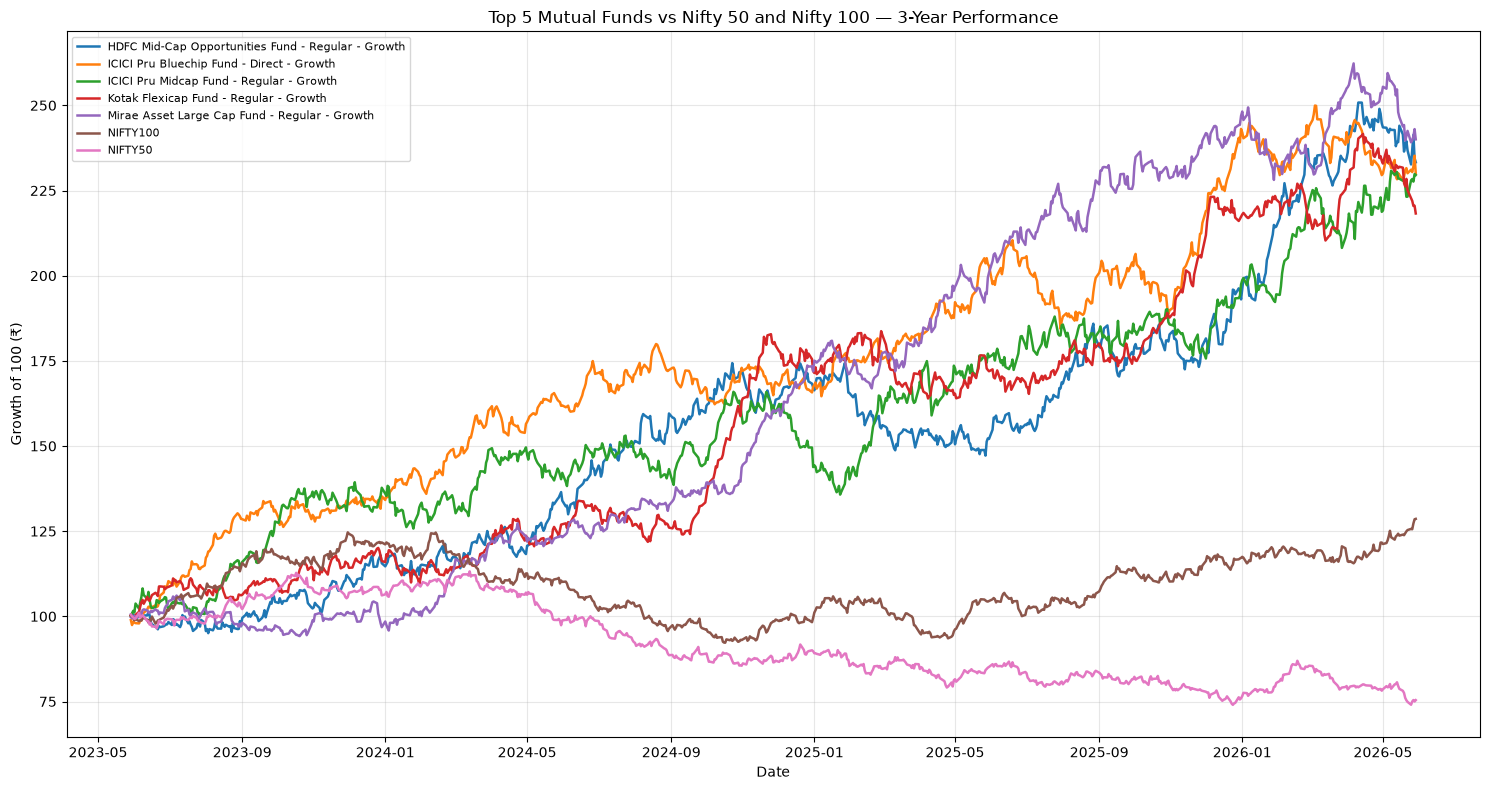

Benchmark chart saved to: D:\Mutual-Fund-Analytics\reports\benchmark_comparison.png
Analysis period: 2023-05-29 to 2026-05-29

Annualized Tracking Error:


,scheme_name,benchmark,tracking_error_pct,observations
0,Mirae Asset Large Cap Fund - Regular - Growth,NIFTY50,19.182,785
1,Mirae Asset Large Cap Fund - Regular - Growth,NIFTY100,18.787,785
2,ICICI Pru Midcap Fund - Regular - Growth,NIFTY50,22.831,785
3,ICICI Pru Midcap Fund - Regular - Growth,NIFTY100,23.251,785
4,Kotak Flexicap Fund - Regular - Growth,NIFTY50,20.495,785
5,Kotak Flexicap Fund - Regular - Growth,NIFTY100,20.641,785
6,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,NIFTY50,22.808,785
7,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,NIFTY100,22.484,785
8,ICICI Pru Bluechip Fund - Direct - Growth,NIFTY50,18.836,785
9,ICICI Pru Bluechip Fund - Direct - Growth,NIFTY100,18.731,785


In [19]:
# STEP 16: Benchmark Comparison Chart + Tracking Error

# 1. Select the top 5 funds from the scorecard
top5 = (
    scorecard_df.sort_values("Fund_Rank")
    .head(5)[["amfi_code", "scheme_name"]]
    .copy()
)

# 2. Calculate daily benchmark returns
benchmark_returns = benchmark_df.sort_values(
    ["index_name", "date"]
).copy()

benchmark_returns["daily_return"] = (
    benchmark_returns.groupby("index_name")["close_value"]
    .pct_change(fill_method=None)
)

# 3. Select the latest 3-year analysis period
end_date = benchmark_returns["date"].max()
start_date = end_date - pd.DateOffset(years=3)

# 4. Prepare daily returns for the top 5 funds
fund_returns = nav_df[
    nav_df["amfi_code"].isin(top5["amfi_code"])
    & (nav_df["date"] >= start_date)
    & (nav_df["date"] <= end_date)
].copy()

fund_returns = fund_returns.merge(
    top5,
    on="amfi_code",
    how="left"
)

fund_returns = fund_returns[
    ["date", "amfi_code", "scheme_name", "daily_return"]
]

# 5. Prepare Nifty 50 and Nifty 100 returns
selected_benchmarks = benchmark_returns[
    benchmark_returns["index_name"].isin(["NIFTY50", "NIFTY100"])
    & (benchmark_returns["date"] >= start_date)
    & (benchmark_returns["date"] <= end_date)
].copy()

benchmark_pivot = selected_benchmarks.pivot(
    index="date",
    columns="index_name",
    values="daily_return"
)

# 6. Align all return series by date
fund_pivot = fund_returns.pivot(
    index="date",
    columns="scheme_name",
    values="daily_return"
)

comparison_returns = fund_pivot.join(
    benchmark_pivot,
    how="inner"
).dropna()

# 7. Convert daily returns into cumulative growth, starting at 100
cumulative_growth = (1 + comparison_returns).cumprod() * 100

# 8. Plot the comparison chart
plt.figure(figsize=(15, 8))

for column in cumulative_growth.columns:
    plt.plot(
        cumulative_growth.index,
        cumulative_growth[column],
        label=column,
        linewidth=1.8
    )

plt.title("Top 5 Mutual Funds vs Nifty 50 and Nifty 100 — 3-Year Performance")
plt.xlabel("Date")
plt.ylabel("Growth of 100 (₹)")
plt.legend(loc="best", fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()

chart_path = output_dir / "benchmark_comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

# 9. Calculate annualized tracking error for each fund vs each benchmark
tracking_error_results = []

for fund in top5["scheme_name"]:
    for benchmark_name in ["NIFTY50", "NIFTY100"]:
        aligned = comparison_returns[[fund, benchmark_name]].dropna()
        active_returns = aligned[fund] - aligned[benchmark_name]

        tracking_error_results.append({
            "scheme_name": fund,
            "benchmark": benchmark_name,
            "tracking_error_annualized": (
                active_returns.std(ddof=1) * np.sqrt(252)
            ),
            "observations": len(active_returns)
        })

tracking_error_df = pd.DataFrame(tracking_error_results)

tracking_error_df["tracking_error_pct"] = (
    tracking_error_df["tracking_error_annualized"] * 100
)

print("Benchmark chart saved to:", chart_path.resolve())
print("Analysis period:", start_date.date(), "to", end_date.date())
print("\nAnnualized Tracking Error:")
display(
    tracking_error_df[
        ["scheme_name", "benchmark", "tracking_error_pct", "observations"]
    ].round(3)
)

In [20]:
# STEP 17: Validate Nifty 100 Benchmark Returns

nifty100 = (
    benchmark_df[benchmark_df["index_name"] == "NIFTY100"]
    .sort_values("date")
    .copy()
)

nifty100["daily_return"] = nifty100["close_value"].pct_change(
    fill_method=None
)

print("NIFTY100 benchmark validation")
print("-" * 40)
print("Rows:", len(nifty100))
print("Start date:", nifty100["date"].min())
print("End date:", nifty100["date"].max())
print("Missing daily returns:", nifty100["daily_return"].isna().sum())
print("Missing closing values:", nifty100["close_value"].isna().sum())
print("Minimum daily return:", nifty100["daily_return"].min())
print("Maximum daily return:", nifty100["daily_return"].max())
print("Mean daily return:", nifty100["daily_return"].mean())
print("Daily return standard deviation:", nifty100["daily_return"].std())

print("\nSample benchmark data:")
display(nifty100.head(10))

NIFTY100 benchmark validation
----------------------------------------
Rows: 1150
Start date: 2022-01-03 00:00:00
End date: 2026-05-29 00:00:00
Missing daily returns: 1
Missing closing values: 0
Minimum daily return: -0.02687297405965361
Maximum daily return: 0.02679498136974412
Mean daily return: 0.00012209381977654413
Daily return standard deviation: 0.008119419678050336

Sample benchmark data:


,date,index_name,close_value,daily_return
3450,2022-01-03,NIFTY100,17778.24,NaN
3451,2022-01-04,NIFTY100,17537.52,-0.013540
3452,2022-01-05,NIFTY100,17607.73,0.004003
3453,2022-01-06,NIFTY100,17556.05,-0.002935
3454,2022-01-07,NIFTY100,17664.02,0.006150
3455,2022-01-10,NIFTY100,17516.51,-0.008351
3456,2022-01-11,NIFTY100,17603.08,0.004942
3457,2022-01-12,NIFTY100,17763.76,0.009128
3458,2022-01-13,NIFTY100,17830.30,0.003746
3459,2022-01-14,NIFTY100,17578.93,-0.014098


In [21]:
# STEP 18: Validate Fund Returns Against NIFTY100

nifty100_returns = (
    benchmark_df[benchmark_df["index_name"] == "NIFTY100"]
    [["date", "close_value"]]
    .sort_values("date")
    .copy()
)

nifty100_returns["nifty100_return"] = (
    nifty100_returns["close_value"].pct_change(fill_method=None)
)

fund_check = nav_df[
    ["amfi_code", "date", "daily_return"]
].merge(
    nifty100_returns[["date", "nifty100_return"]],
    on="date",
    how="inner"
).dropna(subset=["daily_return", "nifty100_return"])

validation_results = []

for scheme, group in fund_check.groupby("amfi_code"):
    validation_results.append({
        "amfi_code": scheme,
        "observations": len(group),
        "fund_return_std": group["daily_return"].std(),
        "nifty100_return_std": group["nifty100_return"].std(),
        "correlation": group["daily_return"].corr(
            group["nifty100_return"]
        )
    })

validation_df = pd.DataFrame(validation_results)

print("Fund-to-NIFTY100 validation")
print("Schemes checked:", len(validation_df))
print("Mean fund return standard deviation:",
      validation_df["fund_return_std"].mean())
print("NIFTY100 daily return standard deviation:",
      validation_df["nifty100_return_std"].iloc[0])
print("Mean fund/NIFTY100 correlation:",
      validation_df["correlation"].mean())

print("\nLowest correlations:")
display(validation_df.nsmallest(5, "correlation"))

print("\nHighest correlations:")
display(validation_df.nlargest(5, "correlation"))

Fund-to-NIFTY100 validation
Schemes checked: 40
Mean fund return standard deviation: 0.00941406241125423
NIFTY100 daily return standard deviation: 0.008119419678050336
Mean fund/NIFTY100 correlation: -0.0022605728131667208

Lowest correlations:


,amfi_code,observations,fund_return_std,nifty100_return_std,correlation
0,100016,1149,0.009164,0.008119,-0.051624
16,119094,1149,0.012225,0.008119,-0.044010
23,120503,1149,0.008746,0.008119,-0.037382
17,119095,1149,0.015790,0.008119,-0.034426
10,118633,1149,0.008817,0.008119,-0.033739



Highest correlations:


,amfi_code,observations,fund_return_std,nifty100_return_std,correlation
11,118634,1149,0.015901,0.008119,0.052849
32,125497,1149,0.009241,0.008119,0.042897
26,120506,1149,0.009594,0.008119,0.035456
28,120841,1149,0.008481,0.008119,0.034805
22,119599,1149,0.015717,0.008119,0.032030


In [22]:
# STEP 19: Inspect One Fund's NAV and Daily Returns

test_code = 125497  # HDFC Top 100, based on your project mapping

fund_sample = (
    nav_df[nav_df["amfi_code"] == test_code]
    .sort_values("date")
    [["amfi_code", "date", "nav", "daily_return"]]
    .copy()
)

print("Fund rows:", len(fund_sample))
print("Start date:", fund_sample["date"].min())
print("End date:", fund_sample["date"].max())
print("Unique NAV values:", fund_sample["nav"].nunique())

print("\nFirst 15 observations:")
display(fund_sample.head(15))

print("\nLast 15 observations:")
display(fund_sample.tail(15))

print("\nNAV and return summary:")
display(fund_sample[["nav", "daily_return"]].describe())

Fund rows: 1150
Start date: 2022-01-03 00:00:00
End date: 2026-05-29 00:00:00
Unique NAV values: 1150

First 15 observations:


,amfi_code,date,nav,daily_return
36800,125497,2022-01-03,560.1443,NaN
36801,125497,2022-01-04,560.7052,0.001001
36802,125497,2022-01-05,563.0884,0.004250
36803,125497,2022-01-06,561.0675,-0.003589
36804,125497,2022-01-07,559.5420,-0.002719
36805,125497,2022-01-10,561.2523,0.003057
36806,125497,2022-01-11,555.8066,-0.009703
36807,125497,2022-01-12,554.3405,-0.002638
36808,125497,2022-01-13,550.4378,-0.007040
36809,125497,2022-01-14,546.4134,-0.007311



Last 15 observations:


,amfi_code,date,nav,daily_return
37935,125497,2026-05-11,1222.6399,0.018189
37936,125497,2026-05-12,1206.6305,-0.013094
37937,125497,2026-05-13,1192.4016,-0.011792
37938,125497,2026-05-14,1192.1357,-0.000223
37939,125497,2026-05-15,1216.6985,0.020604
37940,125497,2026-05-18,1215.1560,-0.001268
37941,125497,2026-05-19,1213.8198,-0.001100
37942,125497,2026-05-20,1199.1005,-0.012126
37943,125497,2026-05-21,1209.7695,0.008898
37944,125497,2026-05-22,1220.6115,0.008962



NAV and return summary:


,nav,daily_return
count,1150.000000,1149.000000
mean,797.454477,0.000710
std,161.260356,0.009241
min,529.635200,-0.031505
25%,671.167675,-0.005546
50%,780.545450,0.000431
75%,860.954925,0.006995
max,1286.062100,0.028407
